# Monthly Customer Retention Analysis

## Objective

This analysis measures the monthly retention of customers in the United Kingdom.

A customer is counted as retained when they are active in both the current month and the previous month. The retention rate is calculated using the formula provided in the assignment:

**Monthly Retention Rate = Retained Customers from Previous Month / Total Active Customers**

December 2011 is excluded from the final comparison because the dataset only includes part of that month, which could make the retention rate misleading.

## 1. Import Libraries and Load the Data

The required libraries are imported for data analysis and visualization. `pandas` is used to work with the dataset, `matplotlib` is used to create charts, and `PercentFormatter` is used to display retention rates as percentages.

The Online Retail dataset is then loaded with the appropriate encoding, and the first few rows are displayed to get an initial view of the data and its columns.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

df = pd.read_csv("OnlineRetail.csv", encoding="ISO-8859-1")
df_original = df.copy()

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
df.shape

(541909, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [ ]:
relevant_columns = [
    "InvoiceNo",
    "InvoiceDate",
    "CustomerID",
    "Country",
    "Quantity",
    "UnitPrice"
]

df[relevant_columns].head()

,InvoiceNo,InvoiceDate,CustomerID,Country,Quantity,UnitPrice
0,536365,12/1/2010 8:26,17850.0,United Kingdom,6,2.55
1,536365,12/1/2010 8:26,17850.0,United Kingdom,6,3.39
2,536365,12/1/2010 8:26,17850.0,United Kingdom,8,2.75
3,536365,12/1/2010 8:26,17850.0,United Kingdom,6,3.39
4,536365,12/1/2010 8:26,17850.0,United Kingdom,6,3.39


For this analysis, the most important fields are the customer identifier, invoice date, country, and transaction information.

Only the columns relevant to identifying customers and their monthly activity are considered.


## 3. Check missing values

In [ ]:
df[relevant_columns].isna().sum()

InvoiceNo           0
InvoiceDate         0
CustomerID     135080
Country             0
Quantity            0
UnitPrice           0
dtype: int64

CustomerID contains missing values. Since customer retention requires tracking the same customer across consecutive months, records without a CustomerID cannot be used in this analysis.

Missing values in unrelated fields, such as Description, do not affect this calculation.


## 4. Convert InvoiceDate to datetime

In [ ]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

In [ ]:
df["InvoiceDate"].agg(["min", "max"])

min   2010-12-01 08:26:00
max   2011-12-09 12:50:00
Name: InvoiceDate, dtype: datetime64[ns]

InvoiceDate is converted to a datetime type so that transactions can be grouped correctly by month.

The date range also confirms that December 2011 is incomplete, which explains why it should not be used in the final comparison.


## 5. Quick data-quality checks

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero unit prices:", (df["UnitPrice"] == 0).sum())

Duplicate rows: 5268
Negative quantities: 10624
Zero unit prices: 2515


A quick quality check shows that the dataset contains duplicate rows and negative quantities, which are commonly associated with returns or cancelled transactions.

These issues are important in a revenue or purchase-behavior analysis. However, the current exercise follows an activity-based retention approach, so no additional transaction filtering is applied here.

Customer-month activity will later be reduced to a binary active/inactive indicator, so repeated transaction rows do not increase a customer's activity count.


## 6. Filter UK customers

In [ ]:
uk_data = df[
    (df["Country"] == "United Kingdom") &
    (df["CustomerID"].notna()) &
    (df["InvoiceDate"].notna())
].copy()

uk_data["CustomerID"] = uk_data["CustomerID"].astype(int)

print("Rows after filtering:", uk_data.shape[0])
print("Unique UK customers:", uk_data["CustomerID"].nunique())

Rows after filtering: 361878
Unique UK customers: 3950


The analysis is restricted to UK customers, as required by the exercise.

Rows without CustomerID are removed because customer-level retention cannot be measured without a valid identifier.


## 7. Create a monthly activity feature

In [ ]:
uk_data["InvoiceMonth"] = uk_data["InvoiceDate"].dt.to_period("M")

uk_data[["InvoiceDate", "InvoiceMonth"]].head()

,InvoiceDate,InvoiceMonth
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12


Retention depends on whether a customer was active in a month, not on how many transaction rows they generated.

Therefore, the data is reduced to unique CustomerID–month combinations before constructing the activity table.


In [ ]:
customer_month = uk_data[["CustomerID", "InvoiceMonth"]].drop_duplicates()

customer_month.head()

,CustomerID,InvoiceMonth
0,17850,2010-12
9,13047,2010-12
46,13748,2010-12
65,15100,2010-12
82,15291,2010-12


## 8. Create the customer-by-month activity table

In [ ]:
activity = pd.crosstab(customer_month["CustomerID"], customer_month["InvoiceMonth"])

activity = (activity > 0).astype(int)

activity.head()

InvoiceMonth,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
CustomerID,,,,,,,,,,,,,
12346,0,1,0,0,0,0,0,0,0,0,0,0,0
12747,1,1,0,1,0,1,1,0,1,0,1,1,1
12748,1,1,1,1,1,1,1,1,1,1,1,1,1
12749,0,0,0,0,0,1,0,0,1,0,0,1,1
12820,0,1,0,0,0,0,0,0,0,1,1,0,1


The crosstab creates a customer-by-month activity matrix.

A value of 1 means that the customer was active during that month, while 0 means that no activity was recorded.


In [ ]:
months = activity.columns.sort_values()
activity = activity[months]

activity.columns

PeriodIndex(['2010-12', '2011-01', '2011-02', '2011-03', '2011-04', '2011-05',
             '2011-06', '2011-07', '2011-08', '2011-09', '2011-10', '2011-11',
             '2011-12'],
            dtype='period[M]', name='InvoiceMonth')

## 9. Calculate monthly retention

In [ ]:
retention_data = []

for i in range(1, len(months)):

    current_month = months[i]
    previous_month = months[i - 1]

    total_customers = activity[current_month].sum()

    retained_customers = ((activity[current_month] == 1) & (activity[previous_month] == 1)).sum()

    retention_rate = retained_customers / total_customers

    retention_data.append({
        "Month": str(current_month),
        "Total Customers": total_customers,
        "Retained Customers": retained_customers,
        "Retention Rate": retention_rate
    })

retention_df = pd.DataFrame(retention_data)
retention_df

,Month,Total Customers,Retained Customers,Retention Rate
0,2011-01,684,322,0.470760
1,2011-02,714,263,0.368347
2,2011-03,923,305,0.330444
3,2011-04,817,310,0.379437
4,2011-05,985,369,0.374619
5,2011-06,943,417,0.442206
6,2011-07,899,379,0.421580
7,2011-08,867,391,0.450980
8,2011-09,1177,417,0.354291
9,2011-10,1285,502,0.390661


In [ ]:
retention_df["Retention Rate (%)"] = (retention_df["Retention Rate"] * 100).round(2)

retention_df

,Month,Total Customers,Retained Customers,Retention Rate,Retention Rate (%)
0,2011-01,684,322,0.470760,47.08
1,2011-02,714,263,0.368347,36.83
2,2011-03,923,305,0.330444,33.04
3,2011-04,817,310,0.379437,37.94
4,2011-05,985,369,0.374619,37.46
5,2011-06,943,417,0.442206,44.22
6,2011-07,899,379,0.421580,42.16
7,2011-08,867,391,0.450980,45.10
8,2011-09,1177,417,0.354291,35.43
9,2011-10,1285,502,0.390661,39.07


The retained-customer count is based on customers who were active in both the current month and the immediately previous month.

The first available retention value is therefore January 2011, because December 2010 is needed as the previous-month reference.


## 10. Exclude incomplete December 2011 from the final comparison

In [ ]:
comparison_df = retention_df[retention_df["Month"] != "2011-12"].copy()

comparison_df

,Month,Total Customers,Retained Customers,Retention Rate,Retention Rate (%)
0,2011-01,684,322,0.470760,47.08
1,2011-02,714,263,0.368347,36.83
2,2011-03,923,305,0.330444,33.04
3,2011-04,817,310,0.379437,37.94
4,2011-05,985,369,0.374619,37.46
5,2011-06,943,417,0.442206,44.22
6,2011-07,899,379,0.421580,42.16
7,2011-08,867,391,0.450980,45.10
8,2011-09,1177,417,0.354291,35.43
9,2011-10,1285,502,0.390661,39.07


December 2011 is retained in the intermediate calculation as a useful data-quality check, but it is excluded from the final comparison.

Because the dataset only covers part of December, the number of active customers is artificially low. Using this incomplete month would make the retention rate misleading.


## 11. Visualize monthly retention

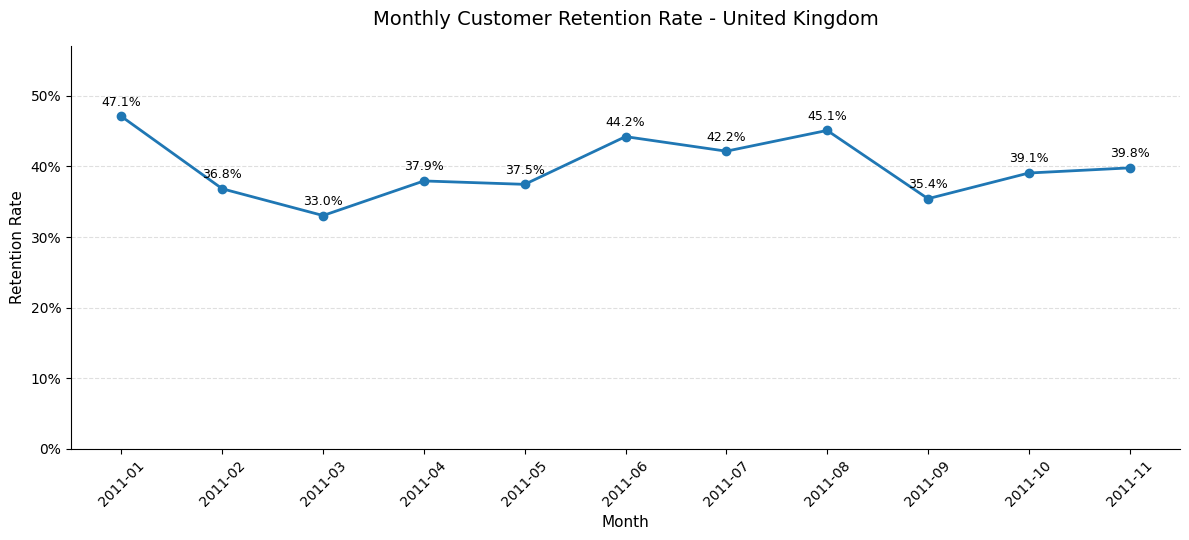

In [ ]:
plt.figure(figsize=(12, 5.5))

plt.plot(
    comparison_df["Month"],
    comparison_df["Retention Rate"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Customer Retention Rate - United Kingdom", fontsize=14,pad=15)

plt.xlabel("Month", fontsize=11)
plt.ylabel("Retention Rate", fontsize=11)

plt.gca().yaxis.set_major_formatter(PercentFormatter(1))

plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.ylim(0, comparison_df["Retention Rate"].max() + 0.1)

for month, rate in zip(
    comparison_df["Month"],
    comparison_df["Retention Rate"]
):
    plt.text(month, rate + 0.015, f"{rate:.1%}", ha="center", fontsize=9)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Findings

Monthly retention is not constant across the period.

Retention declines during the first months of 2011, then improves during parts of the summer before dropping again in September. October and November show a moderate recovery.

December 2011 is not included in the final comparison because the month is incomplete. Its unusually high calculated retention rate is a good example of why incomplete reporting periods should be treated carefully when comparing time-based metrics.


### Analytical Note

Retention can be defined differently depending on the business question.

In some applications, the denominator is the number of active customers in the previous month. In this notebook, the denominator is the total active customers in the current month because this is the definition explicitly provided by the exercise.

The raw dataset also contains returns and cancellations. For a production-level purchase-retention metric, the business definition of a valid purchase should be established first, and return-only or cancelled transactions may need to be excluded.
